# Practical 5 — Text-to-Image Generation using Stable Diffusion
Saumyajeet Singh Bhati -
202401110065

Batch: A1

**Aim:** Implement a pretrained Stable Diffusion model with Hugging Face Diffusers and compare inference steps, classifier-free guidance, and sampling schedulers.

**Theme:** A futuristic eco-friendly library in a forest (different from the reference notebook).

**Platform:** Google Colab with GPU runtime (Runtime → Change runtime type → T4 GPU).

## 1. Install dependencies

In [1]:
%pip -q install "diffusers>=0.30,<1" "transformers>=4.40,<5" accelerate safetensors matplotlib pandas

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


## 2. Import libraries and load pretrained model
We use `segmind/tiny-sd`, a lightweight pretrained Stable Diffusion variant. GPU is strongly recommended.

In [2]:
import time, gc
import torch, pandas as pd, matplotlib.pyplot as plt
from diffusers import StableDiffusionPipeline, DDIMScheduler, EulerDiscreteScheduler, EulerAncestralDiscreteScheduler, DPMSolverMultistepScheduler
from IPython.display import display

assert torch.cuda.is_available(), "Please enable GPU: Runtime > Change runtime type > T4 GPU"
device = "cuda"
model_id = "segmind/tiny-sd"
pipe = StableDiffusionPipeline.from_pretrained(model_id, torch_dtype=torch.float16, safety_checker=None, requires_safety_checker=False).to(device)
pipe.enable_attention_slicing()
pipe.set_progress_bar_config(disable=True)
base_scheduler_config = pipe.scheduler.config
print("Model:", model_id, "| GPU:", torch.cuda.get_device_name(0))

Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model_index.json:   0%|          | 0.00/584 [00:00<?, ?B/s]

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

scheduler_config.json:   0%|          | 0.00/691 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/737 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/722 [00:00<?, ?B/s]

... (7 outputs left out)

vae/diffusion_pytorch_model.bin:   0%|          | 0.00/167M [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/unet.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


Model: segmind/tiny-sd | GPU: Tesla T4


## 3. Text prompt and reusable generation function
We fix the seed for fair comparisons. The prompt, image size, and other parameters remain unchanged unless explicitly tested.

In [3]:
PROMPT = "A futuristic glass library in a lush forest, solar panels on the roof, wooden walkway, golden morning light, cinematic architectural photography, highly detailed"
NEGATIVE = "blurry, low resolution, distorted architecture, text, watermark"
SEED = 123

def generate(prompt=PROMPT, steps=25, guidance=7.5, scheduler=None, negative=NEGATIVE):
    if scheduler is not None:
        pipe.scheduler = scheduler.from_config(base_scheduler_config)
    generator = torch.Generator(device=device).manual_seed(SEED)
    start = time.perf_counter()
    with torch.inference_mode():
        img = pipe(prompt, negative_prompt=negative, num_inference_steps=steps,
                   guidance_scale=guidance, generator=generator, height=384, width=384).images[0]
    return img, round(time.perf_counter()-start, 2)

def gallery(images, labels, columns=3):
    rows = (len(images)+columns-1)//columns
    fig, axes = plt.subplots(rows, columns, figsize=(5*columns, 5*rows))
    axes = list(axes.flat) if hasattr(axes, "flat") else [axes]
    for ax, im, label in zip(axes, images, labels):
        ax.imshow(im); ax.set_title(label); ax.axis("off")
    for ax in axes[len(images):]: ax.axis("off")
    plt.tight_layout(); plt.show()

## 4. Generate the baseline image

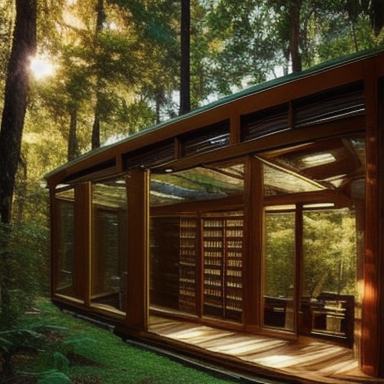

Baseline: 25 steps, guidance 7.5, time 5.13s


In [4]:
baseline, baseline_time = generate()
display(baseline)
print(f"Baseline: 25 steps, guidance 7.5, time {baseline_time}s")

## 5. Experiment A — Inference steps
**Independent variable:** steps = 8, 16, 28, 40. **Controlled:** prompt, seed, guidance = 7.5, default scheduler. Compare visual detail and runtime.

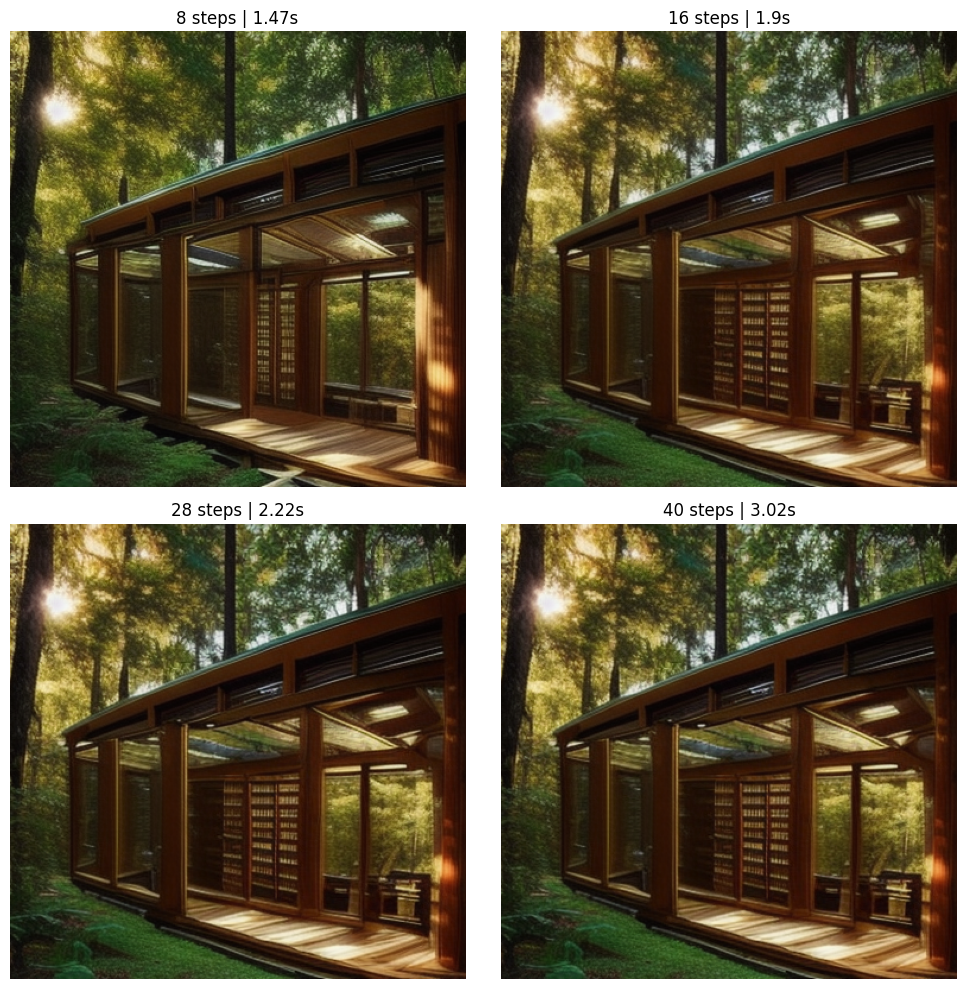

,Steps,Seconds
0,8,1.47
1,16,1.90
2,28,2.22
3,40,3.02


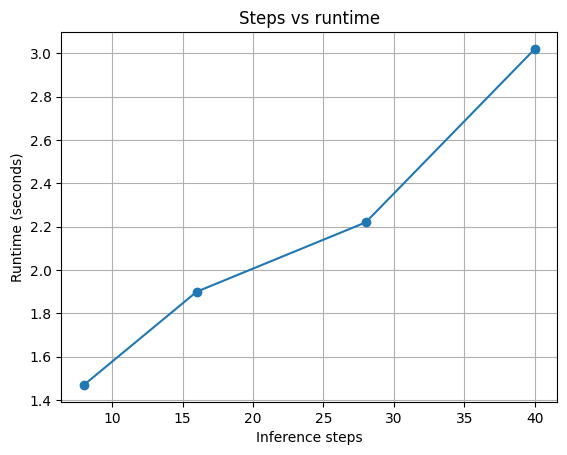

In [5]:
pipe.scheduler = type(pipe.scheduler).from_config(base_scheduler_config)
step_values = [8, 16, 28, 40]
step_images, step_records = [], []
for s in step_values:
    img, seconds = generate(steps=s)
    step_images.append(img)
    step_records.append({"Steps":s, "Seconds":seconds})
gallery(step_images, [f"{r['Steps']} steps | {r['Seconds']}s" for r in step_records], 2)
display(pd.DataFrame(step_records))
plt.plot([r['Steps'] for r in step_records], [r['Seconds'] for r in step_records], marker='o')
plt.xlabel('Inference steps'); plt.ylabel('Runtime (seconds)'); plt.title('Steps vs runtime'); plt.grid(); plt.show()

**Analysis to write after running:** Does architectural detail improve from 8 to 28 steps? Does 40 steps justify its extra time? Note that results depend on model and hardware.

## 6. Experiment B — Guidance scale
**Independent variable:** guidance = 1.0, 3.5, 7.5, 11.0, 16.0. **Controlled:** 25 steps, same seed and default scheduler.

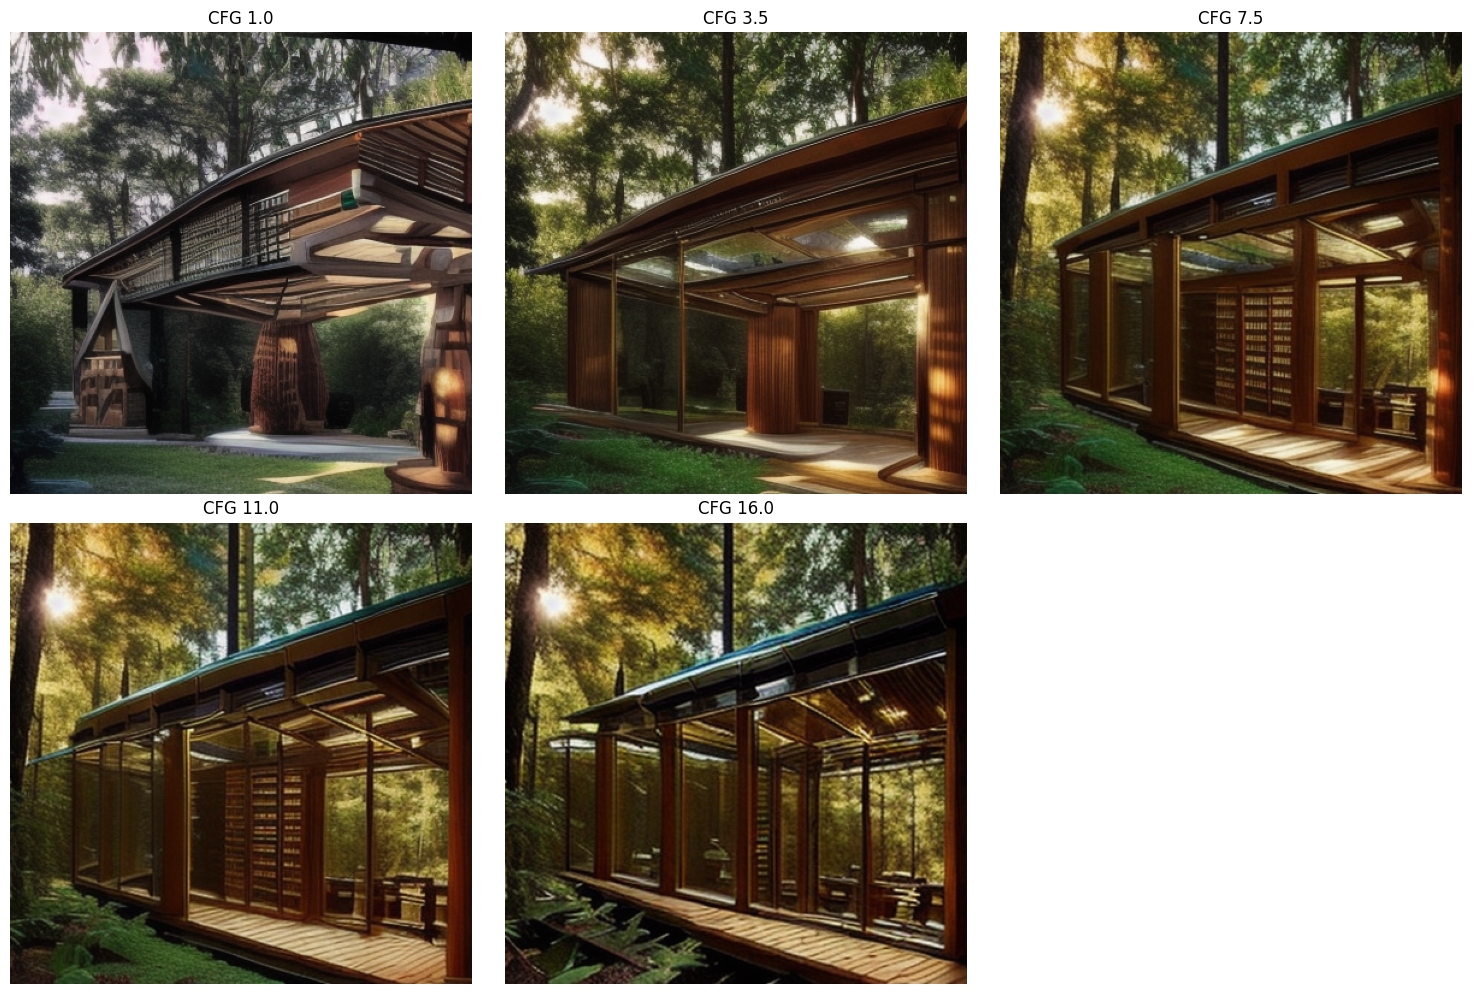

,Guidance,Seconds
0,1.0,1.78
1,3.5,2.68
2,7.5,1.73
3,11.0,1.75
4,16.0,1.67


In [6]:
pipe.scheduler = type(pipe.scheduler).from_config(base_scheduler_config)
guidance_values = [1.0, 3.5, 7.5, 11.0, 16.0]
guidance_images, guidance_records = [], []
for g in guidance_values:
    img, seconds = generate(steps=25, guidance=g)
    guidance_images.append(img)
    guidance_records.append({"Guidance":g, "Seconds":seconds})
gallery(guidance_images, [f"CFG {g}" for g in guidance_values], 3)
display(pd.DataFrame(guidance_records))

**Analysis to write after running:** Compare prompt adherence, color, contrast, and visual artifacts. High guidance can increase prompt adherence but does not guarantee better aesthetics.

## 7. Experiment C — Sampling methods (schedulers)
Compare DDIM, Euler, Euler Ancestral, and DPM-Solver++ with the same prompt, seed, 25 steps and guidance 7.5.

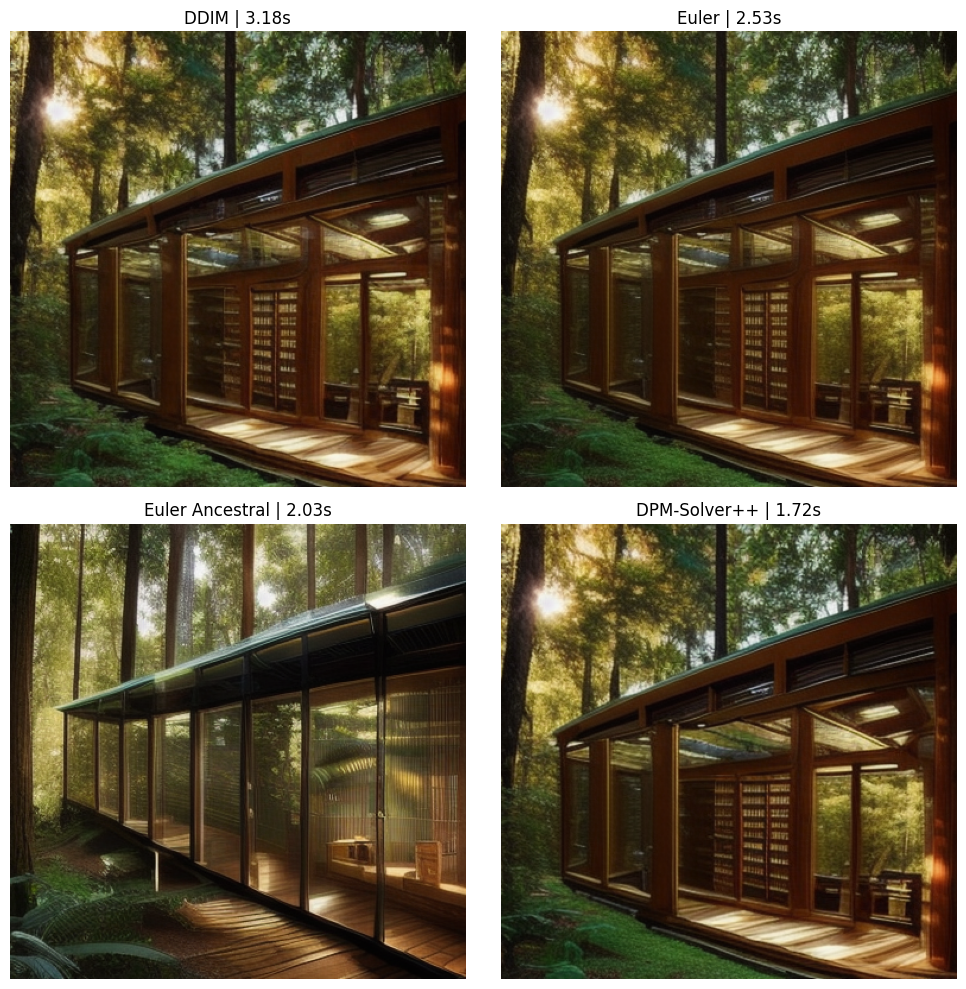

,Scheduler,Seconds
0,DDIM,3.18
1,Euler,2.53
2,Euler Ancestral,2.03
3,DPM-Solver++,1.72


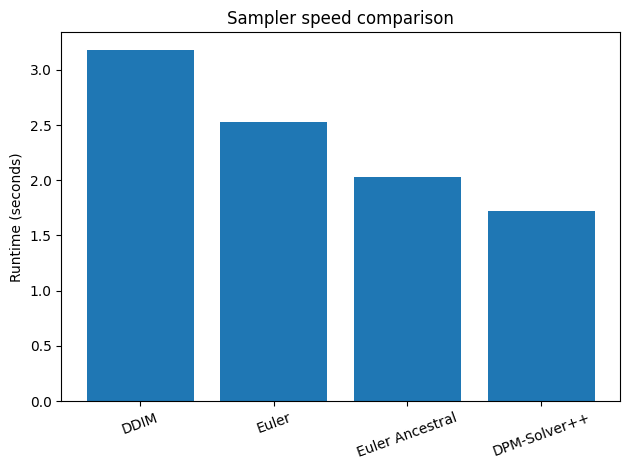

In [7]:
schedulers = {
    "DDIM": DDIMScheduler,
    "Euler": EulerDiscreteScheduler,
    "Euler Ancestral": EulerAncestralDiscreteScheduler,
    "DPM-Solver++": DPMSolverMultistepScheduler,
}
scheduler_images, scheduler_records = [], []
for name, cls in schedulers.items():
    img, seconds = generate(steps=25, guidance=7.5, scheduler=cls)
    scheduler_images.append(img)
    scheduler_records.append({"Scheduler":name, "Seconds":seconds})
gallery(scheduler_images, [f"{r['Scheduler']} | {r['Seconds']}s" for r in scheduler_records], 2)
df = pd.DataFrame(scheduler_records)
display(df)
plt.bar(df['Scheduler'], df['Seconds']); plt.xticks(rotation=20); plt.ylabel('Runtime (seconds)'); plt.title('Sampler speed comparison'); plt.tight_layout(); plt.show()

**Analysis to write after running:** Which sampler best preserves the library structure? Which produces more texture? Compare measured runtime rather than assuming a sampler is always fastest.

## 8. Experiment D — Prompt specificity (extra experiment)
See how adding context to the prompt changes the output with fixed settings.

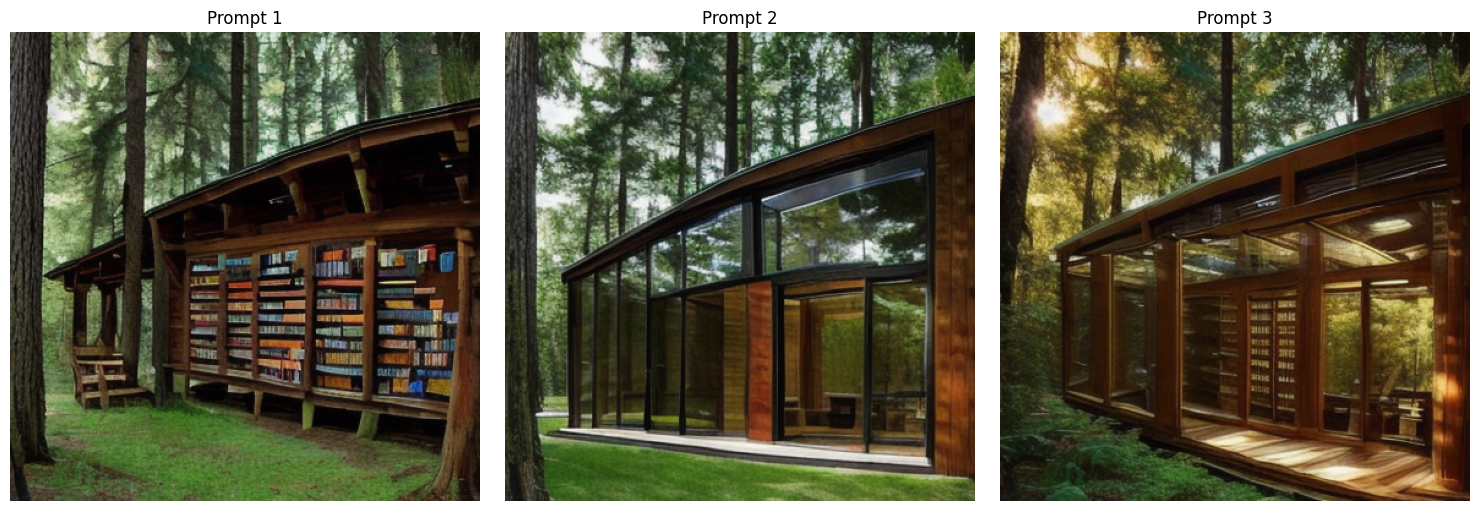

Prompt 1: A library in a forest

Prompt 2: A modern glass library surrounded by tall green trees

Prompt 3: A futuristic glass library in a lush forest, solar panels on the roof, wooden walkway, golden morning light, cinematic architectural photography, highly detailed



In [8]:
pipe.scheduler = DDIMScheduler.from_config(base_scheduler_config)
prompts = [
    "A library in a forest",
    "A modern glass library surrounded by tall green trees",
    PROMPT,
]
imgs = [generate(prompt=p, steps=25, guidance=7.5)[0] for p in prompts]
gallery(imgs, [f"Prompt {i+1}" for i in range(len(prompts))], 3)
for i, p in enumerate(prompts, 1): print(f"Prompt {i}: {p}\n")

In [9]:
import os
os.makedirs('stable_diffusion_results', exist_ok=True)
baseline.save('stable_diffusion_results/baseline.png')
for i, img in enumerate(step_images): img.save(f'stable_diffusion_results/steps_{step_values[i]}.png')
for i, img in enumerate(guidance_images): img.save(f'stable_diffusion_results/guidance_{guidance_values[i]}.png')
for i, img in enumerate(scheduler_images): img.save(f'stable_diffusion_results/scheduler_{i+1}.png')
pd.DataFrame(step_records).to_csv('stable_diffusion_results/step_timings.csv', index=False)
pd.DataFrame(scheduler_records).to_csv('stable_diffusion_results/scheduler_timings.csv', index=False)
print('Saved to stable_diffusion_results/')

Saved to stable_diffusion_results/


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/605M [00:00<?, ?B/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

,Experiment,Setting,CLIP Score
0,Inference steps,8,31.92
1,Inference steps,16,32.09
2,Inference steps,28,32.02
3,Inference steps,40,31.96
4,Guidance scale,1.0,30.68
5,Guidance scale,3.5,32.21
6,Guidance scale,7.5,32.00
7,Guidance scale,11.0,33.34
8,Guidance scale,16.0,32.53
9,Sampler,DDIM,33.04


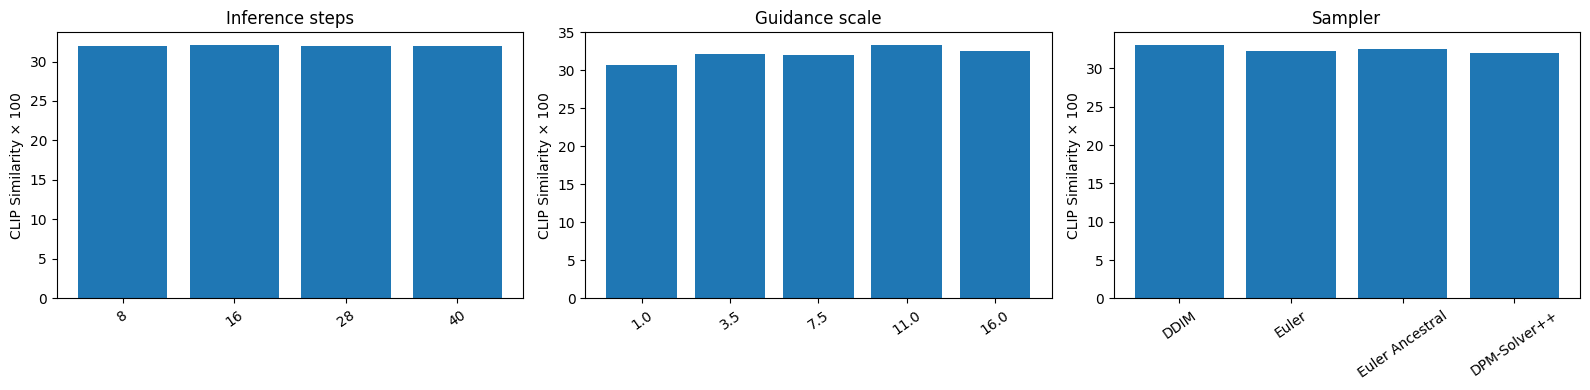

In [10]:

from transformers import CLIPModel, CLIPProcessor
import torch
import pandas as pd
import matplotlib.pyplot as plt

# Load pretrained CLIP model
clip_device = "cpu"
clip_model = CLIPModel.from_pretrained(
    "openai/clip-vit-base-patch32"
).to(clip_device).eval()

clip_processor = CLIPProcessor.from_pretrained(
    "openai/clip-vit-base-patch32"
)

# Calculate text-image similarity
@torch.inference_mode()
def clip_score(image, prompt=PROMPT):
    inputs = clip_processor(
        text=[prompt],
        images=[image],
        return_tensors="pt",
        padding=True,
        truncation=True
    ).to(clip_device)

    outputs = clip_model(**inputs)

    text_features = torch.nn.functional.normalize(
        outputs.text_embeds, dim=-1
    )
    image_features = torch.nn.functional.normalize(
        outputs.image_embeds, dim=-1
    )

    similarity = (text_features * image_features).sum()
    return round(similarity.item() * 100, 2)

# Evaluate all generated images
results = []

experiments = [
    ("Inference steps", step_values, step_images),
    ("Guidance scale", guidance_values, guidance_images),
    ("Sampler", list(schedulers.keys()), scheduler_images)
]

for experiment, values, images in experiments:
    for value, image in zip(values, images):
        results.append({
            "Experiment": experiment,
            "Setting": str(value),
            "CLIP Score": clip_score(image)
        })

# Display results
clip_df = pd.DataFrame(results)
display(clip_df)

# Visual comparison
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (name, group) in zip(
    axes, clip_df.groupby("Experiment", sort=False)
):
    ax.bar(group["Setting"], group["CLIP Score"])
    ax.set_title(name)
    ax.set_ylabel("CLIP Similarity × 100")
    ax.tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()


## 10. Conclusion
- **Inference steps:** More steps generally allow additional refinement but increase runtime; improvements may diminish.
- **Guidance scale:** Controls how strongly the prompt influences generation; very high values may introduce artifacts.
- **Scheduler:** Different numerical sampling strategies produce different images and runtime characteristics even with fixed settings.
- **Prompt specificity:** Detailed prompts can provide more control over composition and style.

**Result:** Implemented text-to-image generation using a pretrained Stable Diffusion pipeline and designed controlled experiments to study key inference parameters.